<a href="https://colab.research.google.com/github/harsha-vardhann-reddy/Deep-Learning-Session/blob/main/Week_8_DLAC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cpu
No GPU detected. This run will measure CPU inference.
For GPU timing, choose Runtime > Change runtime type > GPU.

Demo model created.
Sample input data ready: 256 images

========== PIPELINE STAGE TIMINGS ==========


,Pipeline stage,Median time (ms)
2,Model inference,54.425
0,DataLoader batch,0.309
1,CPU preprocessing,0.237



========== BATCH SIZE BENCHMARK ==========


,Batch size,Latency per batch (ms),Images per second
0,1,1.639,610.2
1,8,11.731,681.9
2,32,55.066,581.1
3,64,132.413,483.3


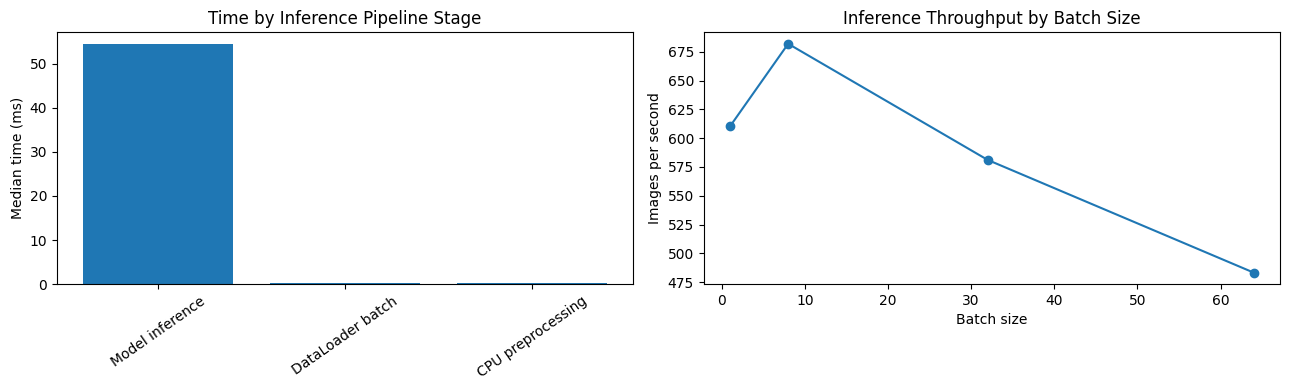


========== BOTTLENECK SUMMARY ==========
Slowest measured stage: Model inference
Likely issue: model computation on the selected device.

INFERENCE PATH BENCHMARK COMPLETED!


In [2]:
# GPU INFERENCE EXECUTION PATH
# Data loading -> Preprocessing -> CPU-to-GPU transfer
# -> Model inference -> GPU-to-CPU output

import time
import statistics
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

# 1. Check the device
use_gpu = torch.cuda.is_available()
device = torch.device("cuda" if use_gpu else "cpu")

print("Device:", device)
if use_gpu:
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. This run will measure CPU inference.")
    print("For GPU timing, choose Runtime > Change runtime type > GPU.")

def sync_device():
    # CUDA work runs asynchronously, so wait for it before measuring.
    if use_gpu:
        torch.cuda.synchronize()

# 2. Create a small demo CNN
class DemoCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.layers(x)

model = DemoCNN().to(device).eval()
print("\nDemo model created.")

# 3. Make sample image data in CPU memory
# These are random images for benchmarking, not real predictions.
images = torch.randint(0, 256, (256, 3, 64, 64), dtype=torch.uint8)
labels = torch.zeros(256, dtype=torch.long)

dataset = TensorDataset(images, labels)
loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)
loader_iterator = iter(loader)

def get_next_batch():
    global loader_iterator
    try:
        return next(loader_iterator)
    except StopIteration:
        loader_iterator = iter(loader)
        return next(loader_iterator)

print(f"Sample input data ready: {len(dataset)} images")

# 4. Get one batch and define the pipeline stages
raw_batch, _ = get_next_batch()

def preprocess():
    # Convert image bytes to floating-point values between 0 and 1.
    return raw_batch.float().div(255.0)

cpu_batch = preprocess()

def transfer_to_device():
    return cpu_batch.to(device)

device_batch = transfer_to_device()

def run_inference():
    with torch.inference_mode():
        return model(device_batch)

# Warm up the model before timing it
for _ in range(5):
    _ = run_inference()
sync_device()

# 5. Measure the time for each stage
def measure_median_ms(function, repeats=20, wait_for_gpu=False):
    for _ in range(2):
        _ = function()

    timings = []
    for _ in range(repeats):
        if wait_for_gpu:
            sync_device()

        start = time.perf_counter()
        _ = function()

        if wait_for_gpu:
            sync_device()

        timings.append((time.perf_counter() - start) * 1000)

    return statistics.median(timings)

stage_times = {
    "DataLoader batch": measure_median_ms(get_next_batch),
    "CPU preprocessing": measure_median_ms(preprocess),
}

if use_gpu:
    stage_times["CPU-to-GPU transfer"] = measure_median_ms(
        transfer_to_device, wait_for_gpu=True
    )

stage_times["Model inference"] = measure_median_ms(
    run_inference, wait_for_gpu=use_gpu
)

if use_gpu:
    output = run_inference()

    def transfer_output_to_cpu():
        return output.detach().cpu()

    stage_times["GPU-to-CPU output transfer"] = measure_median_ms(
        transfer_output_to_cpu, wait_for_gpu=True
    )

stage_df = pd.DataFrame([
    {"Pipeline stage": stage, "Median time (ms)": round(ms, 3)}
    for stage, ms in stage_times.items()
]).sort_values("Median time (ms)", ascending=False)

print("\n========== PIPELINE STAGE TIMINGS ==========")
display(stage_df)

# 6. Compare inference latency at different batch sizes
batch_sizes = [1, 8, 32, 64]
benchmark_rows = []

for batch_size in batch_sizes:
    test_batch = torch.rand(batch_size, 3, 64, 64).to(device)

    with torch.inference_mode():
        for _ in range(5):
            _ = model(test_batch)
    sync_device()

    round_times = []
    for _ in range(3):
        sync_device()
        start = time.perf_counter()

        with torch.inference_mode():
            for _ in range(20):
                _ = model(test_batch)

        sync_device()
        elapsed_ms = (time.perf_counter() - start) * 1000
        round_times.append(elapsed_ms / 20)

    latency_ms = statistics.median(round_times)
    throughput = batch_size / (latency_ms / 1000)

    benchmark_rows.append({
        "Batch size": batch_size,
        "Latency per batch (ms)": round(latency_ms, 3),
        "Images per second": round(throughput, 1),
    })

benchmark_df = pd.DataFrame(benchmark_rows)

print("\n========== BATCH SIZE BENCHMARK ==========")
display(benchmark_df)

# 7. Show charts in the notebook
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(stage_df["Pipeline stage"], stage_df["Median time (ms)"])
axes[0].set_title("Time by Inference Pipeline Stage")
axes[0].set_ylabel("Median time (ms)")
axes[0].tick_params(axis="x", rotation=35)

axes[1].plot(
    benchmark_df["Batch size"],
    benchmark_df["Images per second"],
    marker="o",
)
axes[1].set_title("Inference Throughput by Batch Size")
axes[1].set_xlabel("Batch size")
axes[1].set_ylabel("Images per second")

plt.tight_layout()
plt.show()

# 8. Identify the slowest measured stage
slowest_stage = stage_df.iloc[0]["Pipeline stage"]
print("\n========== BOTTLENECK SUMMARY ==========")
print("Slowest measured stage:", slowest_stage)

if "DataLoader" in slowest_stage:
    print("Likely issue: input batching or data-loading overhead.")
elif "preprocessing" in slowest_stage:
    print("Likely issue: CPU-side image preprocessing.")
elif "CPU-to-GPU" in slowest_stage:
    print("Likely issue: moving input data from CPU memory to GPU memory.")
elif "GPU-to-CPU" in slowest_stage:
    print("Likely issue: copying results back from the GPU.")
else:
    print("Likely issue: model computation on the selected device.")

if use_gpu:
    print("Peak GPU memory used:",
          round(torch.cuda.max_memory_allocated() / (1024 ** 2), 2), "MB")

print("\nINFERENCE PATH BENCHMARK COMPLETED!")